# Preparação do dataset de recortes SEM a região do macrófago

- Autor: Clésio Gonçalves
- Data: 10 ago. 2026
- Esse algoritmo parte dos recortes já gerados em `pre_processamento_dataset_recortes.ipynb` (`dataset_recortes_macrofagos_infectados/`) e remove a região do macrófago de cada recorte.

- **Motivação**: o objetivo do modelo é detectar leishmanias **fora** do macrófago (classe `leishmania`). Como o recorte é centrado no macrófago infectado, a região do macrófago carrega as leishmanias `inside-macrophage`, que não são o alvo dessa detecção. Apagar essa região tende a reduzir a confusão do modelo entre leishmanias intra e extracelulares.

- **Lógica**:
  1. Para cada recorte, identifica as bounding boxes da classe `macrophage`.
  2. Pinta de preto (exclui) a área de cada bbox `macrophage` na imagem do recorte.
  3. Remove do `.txt` as anotações das classes `macrophage` e `inside-macrophage` (deixaram de existir/fazer sentido).
  4. As demais classes (`Non-macrophages`, `leishmania`) são **mantidas** integralmente, mesmo quando o box tem alguma sobreposição com a região apagada — o alvo da detecção (leishmania extracelular) não pode ser descartado.
  5. Salva a nova imagem e o novo `.txt` em `dataset_recortes_macrofagos_infectados_sem_macrofago/<lamina>/`.

- `obj.names` é copiado sem alteração (mantém os mesmos índices de classe), mesmo que `macrophage` e `inside-macrophage` não apareçam mais em nenhum `.txt` de saída.

# Importações e parâmetros gerais

In [1]:
import os
import shutil
from pathlib import Path
from PIL import Image, ImageDraw

In [2]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")

# Diretório de entrada: recortes já gerados (macrófago + leishmanias, ver pre_processamento_dataset_recortes.ipynb)
diretorio_recortes_entrada = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados")

# Diretório de saída: recortes com a região do macrófago excluída
diretorio_recortes_saida = os.path.join(diretorio_raiz, "dataset_recortes_macrofagos_infectados_sem_macrofago")
os.makedirs(diretorio_recortes_saida, exist_ok=True)

# extensão das imagens
extensao = '.png'

# Cor de preenchimento usada para apagar a região do macrófago (preto)
cor_preenchimento = (0, 0, 0)

## Classes de interesse

In [3]:
# obj.names já foi copiado para diretorio_recortes_entrada em pre_processamento_dataset_recortes.ipynb
caminho_obj_names = os.path.join(diretorio_recortes_entrada, "obj.names")
with open(caminho_obj_names) as f:
    classes = [linha.strip() for linha in f]

indice_macrofago = classes.index('macrophage')
indice_inside = classes.index('inside-macrophage')

# Classes removidas por completo: o próprio macrófago e as leishmanias em seu interior
classes_removidas = {indice_macrofago, indice_inside}

print(f"Classes: {classes}")
print(f"Índice 'macrophage': {indice_macrofago} | Índice 'inside-macrophage': {indice_inside}")

Classes: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice 'macrophage': 1 | Índice 'inside-macrophage': 3


## Funções de leitura, mascaramento e filtragem das anotações

In [4]:
# Lê um arquivo de anotação YOLO e retorna lista de (classe, xc, yc, w, h) em pixels
def le_anotacoes(txt_path, largura_img, altura_img):
    boxes = []
    if not os.path.isfile(txt_path):
        return boxes
    with open(txt_path) as f:
        for linha in f:
            linha = linha.strip()
            if not linha:
                continue
            classe_id, xc, yc, w, h = linha.split()
            boxes.append((
                int(classe_id),
                float(xc) * largura_img,
                float(yc) * altura_img,
                float(w) * largura_img,
                float(h) * altura_img,
            ))
    return boxes

In [5]:
# Apaga (preenche com cor_preenchimento) a região de cada bbox de macrófago na imagem do recorte
def mascara_macrofagos(img, boxes_macrofago):
    if not boxes_macrofago:
        return img

    img = img.copy()
    desenho = ImageDraw.Draw(img)
    for _, xc, yc, w, h in boxes_macrofago:
        x1, y1 = xc - w / 2, yc - h / 2
        x2, y2 = xc + w / 2, yc + h / 2
        desenho.rectangle([x1, y1, x2, y2], fill=cor_preenchimento)

    return img


# Remove apenas as anotações de macrophage/inside-macrophage.
# As demais classes (ex.: leishmania) são sempre mantidas, mesmo que
# tenham alguma sobreposição com a região apagada.
def filtra_anotacoes(boxes, tamanho_img):
    boxes_macrofago = [b for b in boxes if b[0] == indice_macrofago]

    novas = []
    for classe_id, xc, yc, w, h in boxes:
        if classe_id in classes_removidas:
            continue
        novas.append((classe_id, xc / tamanho_img, yc / tamanho_img, w / tamanho_img, h / tamanho_img))

    return novas, boxes_macrofago

## Gera os recortes sem a região do macrófago

In [6]:
itens_na_pasta = os.listdir(diretorio_recortes_saida)

if itens_na_pasta:
    print("Os recortes sem macrófago já foram gerados. Geração ignorada.")
else:
    total_recortes = 0
    total_sem_anotacao = 0

    for lamina in sorted(os.listdir(diretorio_recortes_entrada)):
        pasta_lamina_entrada = os.path.join(diretorio_recortes_entrada, lamina)
        if not os.path.isdir(pasta_lamina_entrada):
            continue

        pasta_lamina_saida = os.path.join(diretorio_recortes_saida, lamina)
        os.makedirs(pasta_lamina_saida, exist_ok=True)

        recortes_lamina = 0
        for arquivo in sorted(os.listdir(pasta_lamina_entrada)):
            if not arquivo.endswith(extensao):
                continue

            nome_base = os.path.splitext(arquivo)[0]
            img_path = os.path.join(pasta_lamina_entrada, arquivo)
            txt_path = os.path.join(pasta_lamina_entrada, f"{nome_base}.txt")

            with Image.open(img_path) as img:
                largura_img, altura_img = img.size
                boxes = le_anotacoes(txt_path, largura_img, altura_img)

                anotacoes_filtradas, boxes_macrofago = filtra_anotacoes(boxes, largura_img)
                recorte_sem_macrofago = mascara_macrofagos(img, boxes_macrofago)

                recorte_sem_macrofago.save(os.path.join(pasta_lamina_saida, arquivo))

                with open(os.path.join(pasta_lamina_saida, f"{nome_base}.txt"), "w") as f:
                    for classe_id, xc, yc, w, h in anotacoes_filtradas:
                        f.write(f"{classe_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

                if not anotacoes_filtradas:
                    total_sem_anotacao += 1

            recortes_lamina += 1

        print(f"Lâmina '{lamina}': {recortes_lamina} recortes processados.")
        total_recortes += recortes_lamina

    shutil.copy(caminho_obj_names, diretorio_recortes_saida)
    print(f"\nTotal: {total_recortes} recortes gerados em '{diretorio_recortes_saida}'.")
    print(f"Recortes sem nenhuma anotação restante (apenas macrófago/inside-macrophage): {total_sem_anotacao}")

Lâmina 'leish_1': 96 recortes processados.


Lâmina 'leish_2': 127 recortes processados.


Lâmina 'leish_3': 17 recortes processados.


Lâmina 'leish_4': 126 recortes processados.


Lâmina 'leish_5': 361 recortes processados.


Lâmina 'leish_7': 280 recortes processados.


Lâmina 'leish_8': 353 recortes processados.


Lâmina 'leish_9': 208 recortes processados.

Total: 1568 recortes gerados em '/mnt/arquivos/Doutorado/dataset_recortes_macrofagos_infectados_sem_macrofago'.
Recortes sem nenhuma anotação restante (apenas macrófago/inside-macrophage): 339


## Verificação visual de um recorte

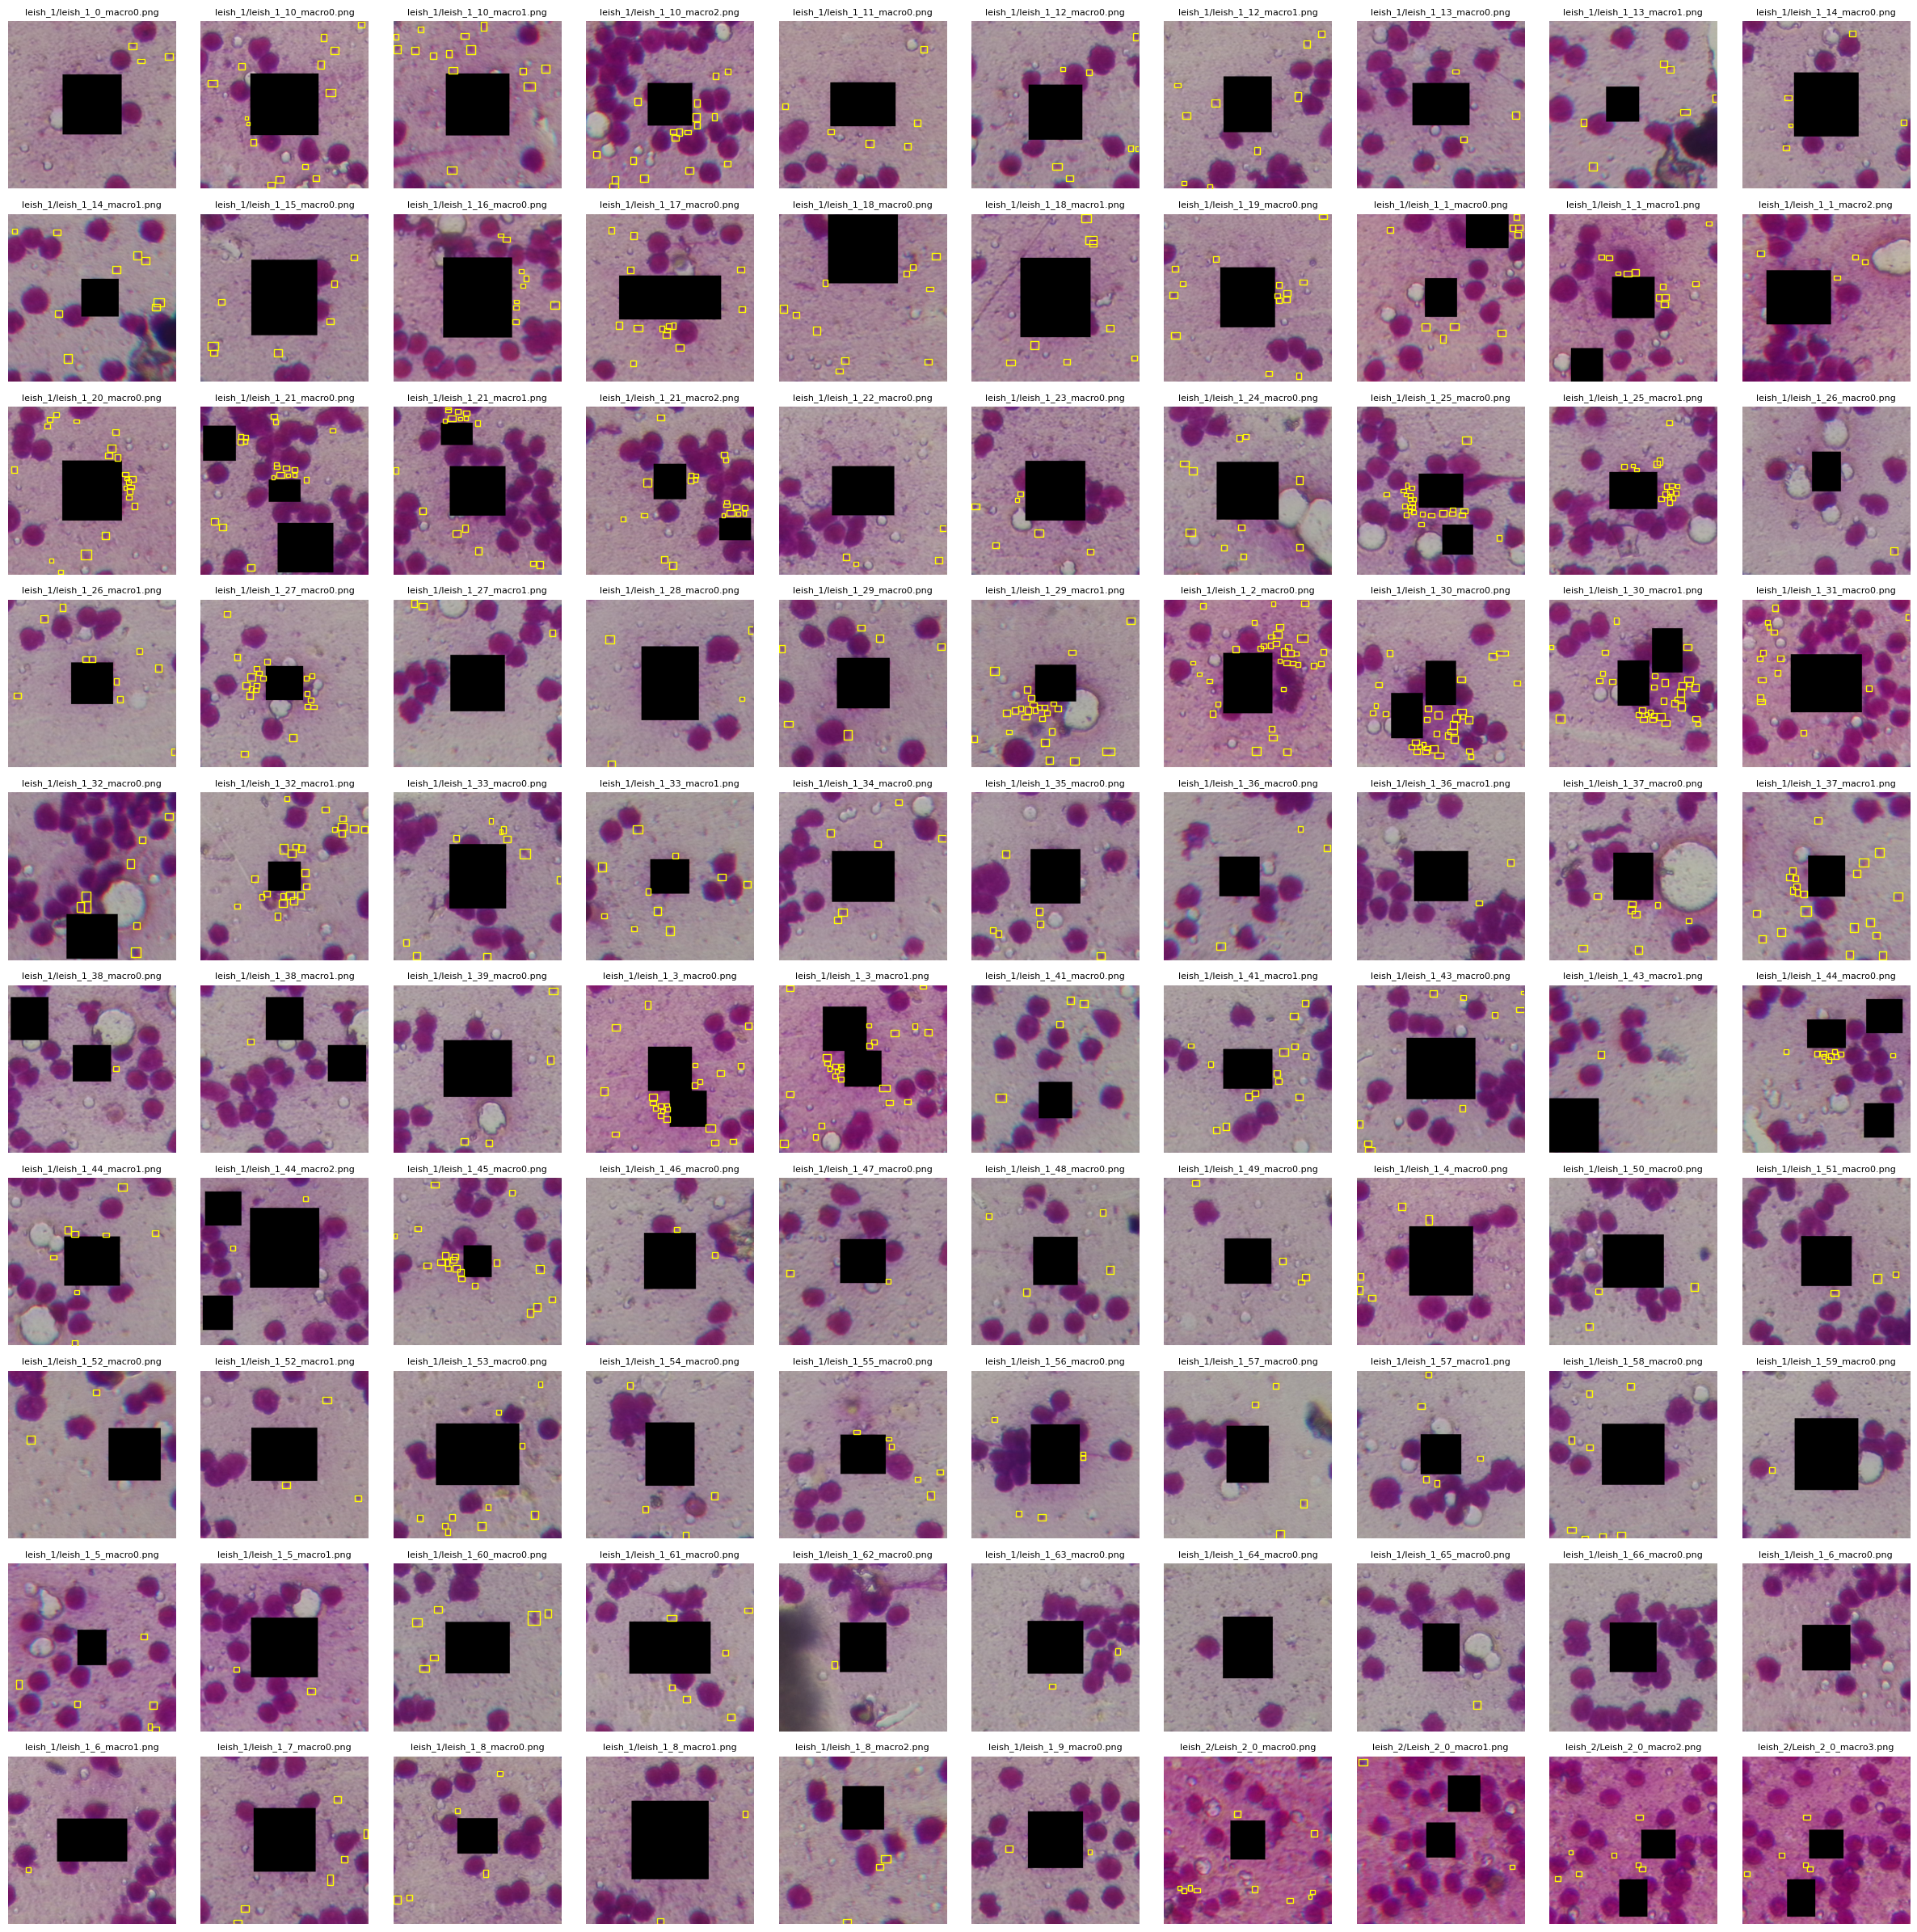

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Coleta até 100 recortes gerados para inspeção visual
arquivos_recortes = []
for lamina in sorted(os.listdir(diretorio_recortes_saida)):
    pasta_lamina = os.path.join(diretorio_recortes_saida, lamina)
    if not os.path.isdir(pasta_lamina):
        continue

    for arquivo in sorted(os.listdir(pasta_lamina)):
        if arquivo.endswith(extensao):
            arquivos_recortes.append((lamina, arquivo))

limite = min(100, len(arquivos_recortes))
if limite == 0:
    print("Nenhum recorte encontrado para visualizar.")
else:
    fig, axes = plt.subplots(10, 10, figsize=(24, 24))
    axes = axes.flatten()

    cores = {indice_macrofago: 'red', indice_inside: 'orange'}

    for ax, (lamina, arquivo) in zip(axes, arquivos_recortes[:limite]):
        img_path = os.path.join(diretorio_recortes_saida, lamina, arquivo)
        nome_base = os.path.splitext(arquivo)[0]

        with Image.open(img_path) as img:
            largura_recorte, altura_recorte = img.size
            ax.imshow(img)

            txt_path = os.path.join(diretorio_recortes_saida, lamina, f"{nome_base}.txt")
            if os.path.exists(txt_path):
                with open(txt_path) as f:
                    for linha in f:
                        linha = linha.strip()
                        if not linha:
                            continue
                        classe_id, xc, yc, w, h = map(float, linha.split())
                        xc, yc, w, h = xc * largura_recorte, yc * altura_recorte, w * largura_recorte, h * altura_recorte
                        x1, y1 = xc - w / 2, yc - h / 2
                        cor = cores.get(int(classe_id), 'yellow')
                        ax.add_patch(patches.Rectangle((x1, y1), w, h, linewidth=1.0, edgecolor=cor, facecolor='none'))

            ax.set_title(f"{lamina}/{arquivo}", fontsize=8)
            ax.axis("off")

    for ax in axes[limite:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()